<a href="https://colab.research.google.com/github/Axcelini/prediccion-cancelacion-reservaciones-hoteleras/blob/main/Equipo3_ModeloClasificacion.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
#punto 3 Documentación del dataset proporcionado
import pandas as pd

df = pd.read_csv('06_cancelacion_reservaciones.csv')

documentacion = pd.DataFrame({
    'Elemento': [
        'Nombre del dataset',
        'Contexto',
        'Fuente',
        'Medio de entrega',
        'Fecha de recepción',
        'Número de observaciones',
        'Número de variables',
        'Formato original',
        'Variable objetivo',
        'Clase positiva',
        'Clase negativa',
        'Descripción general'
    ],
    'Información': [
        '06_cancelacion_reservaciones.csv',
        'Predicción de cancelación de reservaciones hoteleras',
        'Dataset sintético proporcionado por el docente',
        'Archivo proporcionado a través del curso (Canvas)',
        '31 de agosto de 2026',
        f'{df.shape[0]} filas (verificado con Python)',
        f'{df.shape[1]} columnas (verificado con Python)',
        'CSV',
        'reservacion_cancelada',
        '1 = la reservación fue cancelada',
        '0 = la reservación no fue cancelada',
        'Cada fila representa una reservación hotelera individual, con variables sobre '
        'anticipación, tipo de hotel, canal, depósito, composición del grupo, tarifa, '
        'solicitudes especiales, cambios e historial de cancelaciones previas.'
    ]
})

documentacion





,Elemento,Información
0,Nombre del dataset,06_cancelacion_reservaciones.csv
1,Contexto,Predicción de cancelación de reservaciones hot...
2,Fuente,Dataset sintético proporcionado por el docente
3,Medio de entrega,Archivo proporcionado a través del curso (Canvas)
4,Fecha de recepción,31 de agosto de 2026
5,Número de observaciones,1000 filas (verificado con Python)
6,Número de variables,14 columnas (verificado con Python)
7,Formato original,CSV
8,Variable objetivo,reservacion_cancelada
9,Clase positiva,1 = la reservación fue cancelada


In [ ]:
#punto 3 Documentación del dataset proporcionado
import pandas as pd
df = pd.read_csv('06_cancelacion_reservaciones.csv')
print(df.shape)
# Salida: (1000, 14)

(1000, 14)


In [ ]:
#Punto 5 Definici

import pandas as pd

data = {
    "Elemento": [
        "Contexto organizacional",
        "Necesidad organizacional",
        "Unidad de análisis",
        "Variable objetivo",
        "Tipo de problema",
        "Clase negativa",
        "Clase positiva",
        "Usuarios potenciales",
        "Decisión apoyada",
        "Falso positivo",
        "Falso negativo",
        "Riesgo de uso incorrecto",
        "Criterio inicial de éxito",
    ],
    "Información": [
        "Cadena hotelera que busca anticipar cancelaciones de reservaciones",
        "Reducir pérdidas por habitaciones canceladas cerca de la fecha de llegada",
        "Cada fila representa una reservación individual",
        "reservacion_cancelada",
        "Clasificación binaria",
        "0 = reservación no cancelada",
        "1 = reservación cancelada",
        "Equipo de reservaciones, revenue management, gerencia de operaciones",
        "Aplicar overbooking controlado, solicitar depósito de garantía o dar seguimiento personalizado",
        "Se predice cancelación, pero el huésped sí llega: riesgo de reasignar una habitación que sí se necesitaba",
        "Se predice que no se cancelará, pero sí se cancela: la habitación queda vacía sin plan de contingencia",
        "Tomar decisiones automáticas de reasignación sin supervisión humana, afectando a huéspedes reales",
        "Recall aceptable sobre la clase positiva sin sacrificar demasiada precisión, superando claramente al DummyClassifier",
    ],
}

df = pd.DataFrame(data)

# Para visualizar la tabla estilizada dentro del notebook
display(df)

,Elemento,Información
0,Contexto organizacional,Cadena hotelera que busca anticipar cancelacio...
1,Necesidad organizacional,Reducir pérdidas por habitaciones canceladas c...
2,Unidad de análisis,Cada fila representa una reservación individual
3,Variable objetivo,reservacion_cancelada
4,Tipo de problema,Clasificación binaria
5,Clase negativa,0 = reservación no cancelada
6,Clase positiva,1 = reservación cancelada
7,Usuarios potenciales,"Equipo de reservaciones, revenue management, g..."
8,Decisión apoyada,"Aplicar overbooking controlado, solicitar depó..."
9,Falso positivo,"Se predice cancelación, pero el huésped sí lle..."


7. Diccionario de variables

In [ ]:
import pandas as pd

diccionario_variables = pd.DataFrame([
    {
        "Variable": "id_reservacion",
        "Descripción": "Identificador único de la reservación",
        "Tipo orig.": "str",
        "Tipo analítico": "Identificador",
        "Rol": "Identificador",
        "Unidad/Escala": "Código alfanumérico",
        "Faltantes": "0 (0%)",
        "Únicos": 994,
        "Tratamiento": "Excluir del modelo",
        "¿Usar?": "No",
        "Justificación": "No aporta información predictiva; es único por registro",
    },
    {
        "Variable": "dias_anticipacion",
        "Descripción": "Días entre la fecha de reserva y la fecha de llegada",
        "Tipo orig.": "int64",
        "Tipo analítico": "Numérica",
        "Rol": "Predictora",
        "Unidad/Escala": "Días",
        "Faltantes": "0 (0%)",
        "Únicos": 337,
        "Tratamiento": "Escalar (StandardScaler)",
        "¿Usar?": "Sí",
        "Justificación": "Relacionada con el riesgo de cancelación",
    },
    {
        "Variable": "tipo_hotel",
        "Descripción": "Tipo de propiedad reservada",
        "Tipo orig.": "str",
        "Tipo analítico": "Categórica",
        "Rol": "Predictora",
        "Unidad/Escala": "Ciudad / Resort",
        "Faltantes": "0 (0%)",
        "Únicos": 2,
        "Tratamiento": "One-Hot Encoding",
        "¿Usar?": "Sí",
        "Justificación": "Puede influir en el patrón de cancelación",
    },
    {
        "Variable": "canal_reservacion",
        "Descripción": "Canal por el cual se realizó la reservación",
        "Tipo orig.": "str",
        "Tipo analítico": "Categórica",
        "Rol": "Predictora",
        "Unidad/Escala": "4 categorías (tras limpieza)",
        "Faltantes": "0 (0%)",
        "Únicos": "7 → 4 tras limpieza",
        "Tratamiento": "Normalizar texto + One-Hot Encoding",
        "¿Usar?": "Sí",
        "Justificación": "Categorías escritas de forma inconsistente; se homogenizaron",
    },
    {
        "Variable": "tipo_deposito",
        "Descripción": "Tipo de depósito realizado al reservar",
        "Tipo orig.": "str",
        "Tipo analítico": "Categórica",
        "Rol": "Predictora",
        "Unidad/Escala": "Reembolsable / No reembolsable / Sin depósito",
        "Faltantes": "0 (0%)",
        "Únicos": 3,
        "Tratamiento": "One-Hot Encoding",
        "¿Usar?": "Sí",
        "Justificación": "Variable con fuerte relación conceptual con la cancelación",
    },
    {
        "Variable": "adultos",
        "Descripción": "Número de adultos en la reservación",
        "Tipo orig.": "int64",
        "Tipo analítico": "Numérica",
        "Rol": "Predictora",
        "Unidad/Escala": "Personas",
        "Faltantes": "0 (0%)",
        "Únicos": 5,
        "Tratamiento": "Escalar",
        "¿Usar?": "Sí",
        "Justificación": "Describe la composición del grupo",
    },
    {
        "Variable": "menores",
        "Descripción": "Número de menores en la reservación",
        "Tipo orig.": "int64",
        "Tipo analítico": "Numérica",
        "Rol": "Predictora",
        "Unidad/Escala": "Personas",
        "Faltantes": "0 (0%)",
        "Únicos": 4,
        "Tratamiento": "Escalar",
        "¿Usar?": "Sí",
        "Justificación": "Describe la composición del grupo",
    },
    {
        "Variable": "noches",
        "Descripción": "Número de noches reservadas",
        "Tipo orig.": "int64",
        "Tipo analítico": "Numérica",
        "Rol": "Predictora",
        "Unidad/Escala": "Noches",
        "Faltantes": "0 (0%)",
        "Únicos": 14,
        "Tratamiento": "Escalar",
        "¿Usar?": "Sí",
        "Justificación": "Relacionada con el valor y riesgo de la reserva",
    },
    {
        "Variable": "tarifa_promedio_mxn",
        "Descripción": "Tarifa promedio por noche en pesos mexicanos",
        "Tipo orig.": "float64",
        "Tipo analítico": "Numérica",
        "Rol": "Predictora",
        "Unidad/Escala": "MXN",
        "Faltantes": "17 (1.7%)",
        "Únicos": 952,
        "Tratamiento": "Imputar (mediana) + escalar",
        "¿Usar?": "Sí",
        "Justificación": "Variable económica relevante; tiene valores faltantes",
    },
    {
        "Variable": "solicitudes_especiales",
        "Descripción": "Número de solicitudes especiales del huésped",
        "Tipo orig.": "int64",
        "Tipo analítico": "Numérica",
        "Rol": "Predictora",
        "Unidad/Escala": "Cantidad",
        "Faltantes": "0 (0%)",
        "Únicos": 6,
        "Tratamiento": "Escalar",
        "¿Usar?": "Sí",
        "Justificación": "Puede reflejar compromiso con la reservación",
    },
    {
        "Variable": "cambios_reservacion",
        "Descripción": "Número de modificaciones hechas a la reservación",
        "Tipo orig.": "int64",
        "Tipo analítico": "Numérica",
        "Rol": "Predictora",
        "Unidad/Escala": "Cantidad",
        "Faltantes": "0 (0%)",
        "Únicos": 5,
        "Tratamiento": "Escalar",
        "¿Usar?": "Sí",
        "Justificación": "Los cambios frecuentes pueden anticipar cancelación",
    },
    {
        "Variable": "cancelaciones_previas",
        "Descripción": "Cancelaciones previas del mismo cliente",
        "Tipo orig.": "int64",
        "Tipo analítico": "Numérica",
        "Rol": "Predictora",
        "Unidad/Escala": "Cantidad",
        "Faltantes": "0 (0%)",
        "Únicos": 4,
        "Tratamiento": "Escalar",
        "¿Usar?": "Sí",
        "Justificación": "Historial de comportamiento del cliente",
    },
    {
        "Variable": "temporada",
        "Descripción": "Temporada en la que se realiza la estancia",
        "Tipo orig.": "str",
        "Tipo analítico": "Categórica",
        "Rol": "Predictora",
        "Unidad/Escala": "Alta / Media / Baja",
        "Faltantes": "0 (0%)",
        "Únicos": 3,
        "Tratamiento": "One-Hot Encoding",
        "¿Usar?": "Sí",
        "Justificación": "La demanda estacional puede influir en la cancelación",
    },
    {
        "Variable": "reservacion_cancelada",
        "Descripción": "Indica si la reservación fue cancelada",
        "Tipo orig.": "int64",
        "Tipo analítico": "Binaria",
        "Rol": "Objetivo",
        "Unidad/Escala": "0 = No, 1 = Sí",
        "Faltantes": "0 (0%)",
        "Únicos": 2,
        "Tratamiento": "Ninguno (variable objetivo)",
        "¿Usar?": "Sí",
        "Justificación": "Variable a predecir",
    },
])

diccionario_variables

,Variable,Descripción,Tipo orig.,Tipo analítico,Rol,Unidad/Escala,Faltantes,Únicos,Tratamiento,¿Usar?,Justificación
0,id_reservacion,Identificador único de la reservación,str,Identificador,Identificador,Código alfanumérico,0 (0%),994,Excluir del modelo,No,No aporta información predictiva; es único por...
1,dias_anticipacion,Días entre la fecha de reserva y la fecha de l...,int64,Numérica,Predictora,Días,0 (0%),337,Escalar (StandardScaler),Sí,Relacionada con el riesgo de cancelación
2,tipo_hotel,Tipo de propiedad reservada,str,Categórica,Predictora,Ciudad / Resort,0 (0%),2,One-Hot Encoding,Sí,Puede influir en el patrón de cancelación
3,canal_reservacion,Canal por el cual se realizó la reservación,str,Categórica,Predictora,4 categorías (tras limpieza),0 (0%),7 → 4 tras limpieza,Normalizar texto + One-Hot Encoding,Sí,Categorías escritas de forma inconsistente; se...
4,tipo_deposito,Tipo de depósito realizado al reservar,str,Categórica,Predictora,Reembolsable / No reembolsable / Sin depósito,0 (0%),3,One-Hot Encoding,Sí,Variable con fuerte relación conceptual con la...
5,adultos,Número de adultos en la reservación,int64,Numérica,Predictora,Personas,0 (0%),5,Escalar,Sí,Describe la composición del grupo
6,menores,Número de menores en la reservación,int64,Numérica,Predictora,Personas,0 (0%),4,Escalar,Sí,Describe la composición del grupo
7,noches,Número de noches reservadas,int64,Numérica,Predictora,Noches,0 (0%),14,Escalar,Sí,Relacionada con el valor y riesgo de la reserva
8,tarifa_promedio_mxn,Tarifa promedio por noche en pesos mexicanos,float64,Numérica,Predictora,MXN,17 (1.7%),952,Imputar (mediana) + escalar,Sí,Variable económica relevante; tiene valores fa...
9,solicitudes_especiales,Número de solicitudes especiales del huésped,int64,Numérica,Predictora,Cantidad,0 (0%),6,Escalar,Sí,Puede reflejar compromiso con la reservación


In [ ]:
#8 Carga del dataset
import pandas as pd

df = pd.read_csv('06_cancelacion_reservaciones.csv')
print('Filas y columnas:', df.shape)
df.head()


Filas y columnas: (1000, 14)


,id_reservacion,dias_anticipacion,tipo_hotel,canal_reservacion,tipo_deposito,adultos,menores,noches,tarifa_promedio_mxn,solicitudes_especiales,cambios_reservacion,cancelaciones_previas,temporada,reservacion_cancelada
0,RES-0001,281,Ciudad,Agencia en línea,Reembolsable,3,2,13,650.00,5,0,0,Alta,0
1,RES-0002,265,Resort,Agencia física,Sin depósito,3,0,9,2216.16,5,4,1,Alta,0
2,RES-0003,333,Resort,Agencia física,Sin depósito,2,1,9,2964.60,1,0,0,Media,0
3,RES-0004,169,Ciudad,Agencia física,No reembolsable,2,2,7,NaN,0,3,3,Media,1
4,RES-0005,319,Ciudad,Agencia en línea,No reembolsable,3,1,11,1436.58,0,3,0,Alta,0


===== 1. PRIMERAS OBSERVACIONES =====


,id_reservacion,dias_anticipacion,tipo_hotel,canal_reservacion,tipo_deposito,adultos,menores,noches,tarifa_promedio_mxn,solicitudes_especiales,cambios_reservacion,cancelaciones_previas,temporada,reservacion_cancelada
0,RES-0001,281,Ciudad,Agencia en línea,Reembolsable,3,2,13,650.00,5,0,0,Alta,0
1,RES-0002,265,Resort,Agencia física,Sin depósito,3,0,9,2216.16,5,4,1,Alta,0
2,RES-0003,333,Resort,Agencia física,Sin depósito,2,1,9,2964.60,1,0,0,Media,0
3,RES-0004,169,Ciudad,Agencia física,No reembolsable,2,2,7,NaN,0,3,3,Media,1
4,RES-0005,319,Ciudad,Agencia en línea,No reembolsable,3,1,11,1436.58,0,3,0,Alta,0



===== 2. ULTIMAS OBSERVACIONES =====


,id_reservacion,dias_anticipacion,tipo_hotel,canal_reservacion,tipo_deposito,adultos,menores,noches,tarifa_promedio_mxn,solicitudes_especiales,cambios_reservacion,cancelaciones_previas,temporada,reservacion_cancelada
995,RES-0370,198,Resort,Agencia en línea,No reembolsable,2,3,12,2260.12,1,0,0,Baja,0
996,RES-0437,201,Ciudad,Sitio web,Reembolsable,4,2,5,2800.35,2,3,1,Media,0
997,RES-0279,142,Ciudad,Agencia física,No reembolsable,2,3,12,3217.73,3,0,0,Media,0
998,RES-0871,207,Resort,Sitio web,Sin depósito,2,3,12,4714.62,5,1,0,Baja,1
999,RES-0923,19,Resort,Empresa,No reembolsable,3,0,11,3360.47,1,2,1,Baja,0



===== 3. NUMERO DE FILAS Y COLUMNAS =====
(1000, 14)

===== 4. NOMBRES DE VARIABLES =====
['id_reservacion', 'dias_anticipacion', 'tipo_hotel', 'canal_reservacion', 'tipo_deposito', 'adultos', 'menores', 'noches', 'tarifa_promedio_mxn', 'solicitudes_especiales', 'cambios_reservacion', 'cancelaciones_previas', 'temporada', 'reservacion_cancelada']

===== 5. TIPOS DE DATOS =====
id_reservacion             object
dias_anticipacion           int64
tipo_hotel                 object
canal_reservacion          object
tipo_deposito              object
adultos                     int64
menores                     int64
noches                      int64
tarifa_promedio_mxn       float64
solicitudes_especiales      int64
cambios_reservacion         int64
cancelaciones_previas       int64
temporada                  object
reservacion_cancelada       int64
dtype: object

===== 6. ESTADISTICAS DESCRIPTIVAS =====


,dias_anticipacion,adultos,menores,noches,tarifa_promedio_mxn,solicitudes_especiales,cambios_reservacion,cancelaciones_previas,reservacion_cancelada
count,1000.000000,1000.000000,1000.000000,1000.000000,983.000000,1000.000000,1000.000000,1000.000000,1000.000000
mean,188.229000,2.486000,1.531000,7.542000,2661.271536,2.454000,1.994000,0.715000,0.215000
std,106.036901,1.105906,1.124412,4.021742,1052.744067,1.697282,1.405681,0.790189,0.411028
min,0.000000,0.000000,0.000000,1.000000,650.000000,0.000000,0.000000,0.000000,0.000000
25%,102.500000,2.000000,1.000000,4.000000,1899.555000,1.000000,1.000000,0.000000,0.000000
50%,187.000000,2.000000,2.000000,8.000000,2620.170000,2.000000,2.000000,1.000000,0.000000
75%,275.250000,3.000000,3.000000,11.000000,3412.920000,4.000000,3.000000,1.000000,0.000000
max,900.000000,4.000000,3.000000,14.000000,5655.000000,5.000000,4.000000,3.000000,1.000000



===== 7. VALORES UNICOS =====
id_reservacion            994
dias_anticipacion         337
tipo_hotel                  2
canal_reservacion           7
tipo_deposito               3
adultos                     5
menores                     4
noches                     14
tarifa_promedio_mxn       952
solicitudes_especiales      6
cambios_reservacion         5
cancelaciones_previas       4
temporada                   3
reservacion_cancelada       2
dtype: int64

===== 8. VALORES FALTANTES =====
id_reservacion             0
dias_anticipacion          0
tipo_hotel                 0
canal_reservacion          0
tipo_deposito              0
adultos                    0
menores                    0
noches                     0
tarifa_promedio_mxn       17
solicitudes_especiales     0
cambios_reservacion        0
cancelaciones_previas      0
temporada                  0
reservacion_cancelada      0
dtype: int64

===== 9. DUPLICADOS =====
Duplicados: 6

===== 10. DISTRIBUCION DE LA VARIABLE OBJ

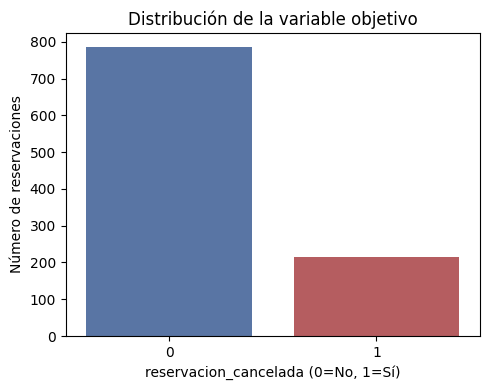

In [ ]:
#9. Realizar la exploración inicial

import matplotlib.pyplot as plt
import seaborn as sns


print("===== 1. PRIMERAS OBSERVACIONES =====")
display(df.head())

print("\n===== 2. ULTIMAS OBSERVACIONES =====")
display(df.tail())

print("\n===== 3. NUMERO DE FILAS Y COLUMNAS =====")
print(df.shape)

print("\n===== 4. NOMBRES DE VARIABLES =====")
print(df.columns.tolist())

print("\n===== 5. TIPOS DE DATOS =====")
print(df.dtypes)

print("\n===== 6. ESTADISTICAS DESCRIPTIVAS =====")
display(df.describe())

print("\n===== 7. VALORES UNICOS =====")
print(df.nunique())

print("\n===== 8. VALORES FALTANTES =====")
print(df.isnull().sum())

print("\n===== 9. DUPLICADOS =====")
print('Duplicados:', df.duplicated().sum())

print("\n===== 10. DISTRIBUCION DE LA VARIABLE OBJETIVO =====")
print(df['reservacion_cancelada'].value_counts())



plt.figure(figsize=(5,4))
sns.countplot(x='reservacion_cancelada', data=df, hue='reservacion_cancelada',
              palette=['#4C72B0','#C44E52'], legend=False)
plt.title('Distribución de la variable objetivo')
plt.xlabel('reservacion_cancelada (0=No, 1=Sí)')
plt.ylabel('Número de reservaciones')
plt.tight_layout()
plt.show()

In [ ]:
# 10 Calidad de los datos

import pandas as pd

calidad_de_datos = pd.DataFrame([
    {
        "Problema": "Valores faltantes",
        "Variable(s)": "tarifa_promedio_mxn",
        "Evidencia": "17 valores nulos (1.7%)",
        "Impacto posible": "Sesgo si se ignoran; pérdida de información si se eliminan filas",
        "Tratamiento propuesto": "Imputar con la mediana dentro del pipeline",
        "Justificación": "La mediana es robusta a valores extremos de tarifa",
    },
    {
        "Problema": "Duplicados",
        "Variable(s)": "Registro completo (id_reservacion)",
        "Evidencia": "6 filas idénticas",
        "Impacto posible": "Sobrerrepresentación de esos casos, sesgo en el entrenamiento",
        "Tratamiento propuesto": "Eliminar duplicados exactos antes de dividir",
        "Justificación": "No aportan información nueva y distorsionan las proporciones",
    },
    {
        "Problema": "Categorías inconsistentes",
        "Variable(s)": "canal_reservacion",
        "Evidencia": "'Empresa'/'EMPRESA', 'Sitio web'/'sitio web', espacio extra",
        "Impacto posible": "El modelo trataría cada variante como una categoría distinta",
        "Tratamiento propuesto": "Normalizar (strip + capitalización uniforme)",
        "Justificación": "Se trata del mismo valor semántico escrito de forma distinta",
    },
    {
        "Problema": "Valores atípicos",
        "Variable(s)": "dias_anticipacion",
        "Evidencia": "Máximo de 900 días vs. percentil 75 de 275",
        "Impacto posible": "Podría distorsionar el escalamiento",
        "Tratamiento propuesto": "Conservar y monitorear (no eliminar); evaluar impacto en el modelo",
        "Justificación": "Podría ser una reservación corporativa real anticipada, no necesariamente un error",
    },
    {
        "Problema": "Rangos imposibles",
        "Variable(s)": "Ninguno detectado",
        "Evidencia": "adultos, menores, noches dentro de rangos plausibles",
        "Impacto posible": "N/A",
        "Tratamiento propuesto": "No se requiere tratamiento adicional",
        "Justificación": "Los rangos observados son consistentes con reservaciones reales",
    },
    {
        "Problema": "Identificadores",
        "Variable(s)": "id_reservacion",
        "Evidencia": "994 valores únicos sobre 1000/994 filas",
        "Impacto posible": "No aporta valor predictivo; podría generar sobreajuste si se incluye",
        "Tratamiento propuesto": "Excluir del entrenamiento",
        "Justificación": "Es un identificador, no una característica del fenómeno a predecir",
    },
])

calidad_de_datos

,Problema,Variable(s),Evidencia,Impacto posible,Tratamiento propuesto,Justificación
0,Valores faltantes,tarifa_promedio_mxn,17 valores nulos (1.7%),Sesgo si se ignoran; pérdida de información si...,Imputar con la mediana dentro del pipeline,La mediana es robusta a valores extremos de ta...
1,Duplicados,Registro completo (id_reservacion),6 filas idénticas,"Sobrerrepresentación de esos casos, sesgo en e...",Eliminar duplicados exactos antes de dividir,No aportan información nueva y distorsionan la...
2,Categorías inconsistentes,canal_reservacion,"'Empresa'/'EMPRESA', 'Sitio web'/'sitio web', ...",El modelo trataría cada variante como una cate...,Normalizar (strip + capitalización uniforme),Se trata del mismo valor semántico escrito de ...
3,Valores atípicos,dias_anticipacion,Máximo de 900 días vs. percentil 75 de 275,Podría distorsionar el escalamiento,Conservar y monitorear (no eliminar); evaluar ...,Podría ser una reservación corporativa real an...
4,Rangos imposibles,Ninguno detectado,"adultos, menores, noches dentro de rangos plau...",N/A,No se requiere tratamiento adicional,Los rangos observados son consistentes con res...
5,Identificadores,id_reservacion,994 valores únicos sobre 1000/994 filas,No aporta valor predictivo; podría generar sob...,Excluir del entrenamiento,"Es un identificador, no una característica del..."


11. Revisar el desbalance
Calcula la cantidad y proporción de cada clase.

Explica:

Qué clase es mayoritaria.
Qué clase es minoritaria.
Si existe desbalance.
Por qué accuracy puede ser engañosa.
Qué métricas deberán utilizarse.
Qué ocurriría si el modelo no detecta la clase positiva.

In [ ]:
# Punto 11 - Revisar el desbalance de clases

# Cantidad de registros por clase
conteo_clases = df['reservacion_cancelada'].value_counts().sort_index()

# Porcentaje de cada clase
porcentaje_clases = (
    df['reservacion_cancelada']
    .value_counts(normalize=True)
    .sort_index() * 100
)

print("Cantidad de registros por clase:")
print(conteo_clases)

print("\nPorcentaje de registros por clase:")
print(porcentaje_clases.round(2))

print("\nResumen:")
print(f"Clase 0 - No cancelada: {conteo_clases.get(0, 0)} "
      f"({porcentaje_clases.get(0, 0):.2f}%)")

print(f"Clase 1 - Cancelada: {conteo_clases.get(1, 0)} "
      f"({porcentaje_clases.get(1, 0):.2f}%)")

Cantidad de registros por clase:
reservacion_cancelada
0    785
1    215
Name: count, dtype: int64

Porcentaje de registros por clase:
reservacion_cancelada
0    78.5
1    21.5
Name: proportion, dtype: float64

Resumen:
Clase 0 - No cancelada: 785 (78.50%)
Clase 1 - Cancelada: 215 (21.50%)


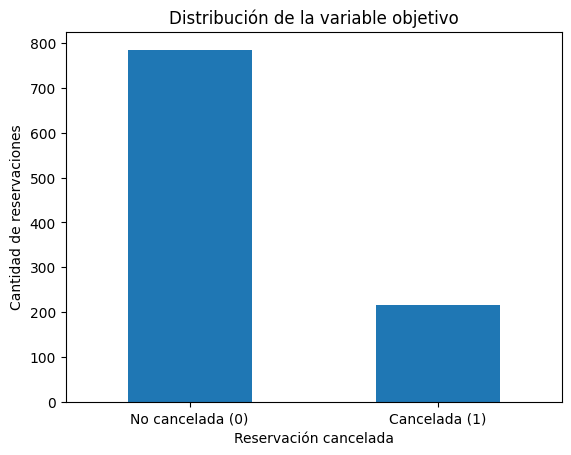

In [ ]:
import matplotlib.pyplot as plt

conteo_clases.plot(kind='bar')

plt.title('Distribución de la variable objetivo')
plt.xlabel('Reservación cancelada')
plt.ylabel('Cantidad de reservaciones')
plt.xticks([0, 1], ['No cancelada (0)', 'Cancelada (1)'], rotation=0)

plt.show()

12. Separar variables predictoras y objetivo
Elimina identificadores únicos y variables no aptas para el entrenamiento.

Sustituye los nombres del ejemplo por los nombres del dataset asignado.

In [ ]:
# Punto 12 - Separación de variables predictoras y objetivo (Eliab)

# Variable objetivo
y = df['reservacion_cancelada']

# Variables predictoras
X = df.drop(columns=['reservacion_cancelada', 'id_reservacion'])

# Mostrar dimensiones
print("Dimensiones de X:", X.shape)
print("Dimensiones de y:", y.shape)

# Mostrar las variables que se utilizarán
print("\nVariables predictoras:")
print(X.columns.tolist())

print("\nVariable objetivo:")
print(y.name)


Dimensiones de X: (1000, 12)
Dimensiones de y: (1000,)

Variables predictoras:
['dias_anticipacion', 'tipo_hotel', 'canal_reservacion', 'tipo_deposito', 'adultos', 'menores', 'noches', 'tarifa_promedio_mxn', 'solicitudes_especiales', 'cambios_reservacion', 'cancelaciones_previas', 'temporada']

Variable objetivo:
reservacion_cancelada


13. Diseñar la estrategia de partición
Utiliza una división (ejemplo) de:

70 % entrenamiento.
30 % prueba.
La partición deberá:

Utilizar estratificación.
Emplear random_state=42.
Conservar las proporciones.
Mantener prueba completamente separada.
Realizar el preprocesamiento después de dividir.
Evitar aplicar remuestreo a validación o prueba.

In [ ]:
# Punto 13 - División estratificada 70/15/15

from sklearn.model_selection import train_test_split

# Primera división: 70% entrenamiento y 30% temporal
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    stratify=y,
    random_state=42
)

# Segunda división: 15% validación y 15% prueba
# Del 30% temporal, se divide mitad y mitad
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    stratify=y_temp,
    random_state=42
)

# Mostrar dimensiones
print("Conjunto de entrenamiento:")
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("\nConjunto de validación:")
print("X_val:", X_val.shape)
print("y_val:", y_val.shape)

print("\nConjunto de prueba:")
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

Conjunto de entrenamiento:
X_train: (700, 12)
y_train: (700,)

Conjunto de validación:
X_val: (150, 12)
y_val: (150,)

Conjunto de prueba:
X_test: (150, 12)
y_test: (150,)


In [ ]:
# Comprobar la distribución de clases en cada conjunto - Punto 13

print("Distribución en entrenamiento:")
print(y_train.value_counts(normalize=True).sort_index().round(3))

print("\nDistribución en validación:")
print(y_val.value_counts(normalize=True).sort_index().round(3))

print("\nDistribución en prueba:")
print(y_test.value_counts(normalize=True).sort_index().round(3))

Distribución en entrenamiento:
reservacion_cancelada
0    0.784
1    0.216
Name: proportion, dtype: float64

Distribución en validación:
reservacion_cancelada
0    0.787
1    0.213
Name: proportion, dtype: float64

Distribución en prueba:
reservacion_cancelada
0    0.787
1    0.213
Name: proportion, dtype: float64


In [ ]:
# punto 14 - Pipeline de preprocesamiento

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

numeric_features = ['dias_anticipacion', 'adultos', 'menores', 'noches',
                     'tarifa_promedio_mxn', 'solicitudes_especiales',
                     'cambios_reservacion', 'cancelaciones_previas']
categorical_features = ['tipo_hotel', 'canal_reservacion',
                         'tipo_deposito', 'temporada']

numeric_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])
categorical_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer([
    ('num', numeric_transformer, numeric_features),
    ('cat', categorical_transformer, categorical_features)
])

documentacion_pipeline = pd.DataFrame({
    'Grupo': [
        'Variables numéricas',
        'Variables categóricas',
        'Transformación numérica',
        'Transformación categórica'
    ],
    'Detalle': [
        ', '.join(numeric_features),
        ', '.join(categorical_features),
        'Imputación (mediana) + StandardScaler',
        "Imputación (más frecuente) + OneHotEncoder (handle_unknown='ignore')"
    ]
})

documentacion_pipeline

,Grupo,Detalle
0,Variables numéricas,"dias_anticipacion, adultos, menores, noches, t..."
1,Variables categóricas,"tipo_hotel, canal_reservacion, tipo_deposito, ..."
2,Transformación numérica,Imputación (mediana) + StandardScaler
3,Transformación categórica,Imputación (más frecuente) + OneHotEncoder (ha...


In [ ]:
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyClassifier

# Assuming df is already loaded and available in the kernel from previous cells
# If df is not loaded, you would need: df = pd.read_csv('06_cancelacion_reservaciones.csv')

# Define X and y (from cell gLL2ur6Z4rLa)
y = df['reservacion_cancelada']
X = df.drop(columns=['reservacion_cancelada', 'id_reservacion'])

# Data split to get X_train, y_train (from cell vjhGt2Yu6wgC)
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    stratify=y,
    random_state=42
)

# Define numeric and categorical features (from cell siPl4CAN79bo)
numeric_features = ['dias_anticipacion', 'adultos', 'menores', 'noches',
                     'tarifa_promedio_mxn', 'solicitudes_especiales',
                     'cambios_reservacion', 'cancelaciones_previas']
categorical_features = ['tipo_hotel', 'canal_reservacion',
                         'tipo_deposito', 'temporada']

# Define transformers (from cell siPl4CAN79bo)
numeric_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])
categorical_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

# Define preprocessor (from cell siPl4CAN79bo)
preprocessor = ColumnTransformer([
    ('num', numeric_transformer, numeric_features),
    ('cat', categorical_transformer, categorical_features)
])

# Original code from the selected cell
dummy_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', DummyClassifier(strategy='most_frequent', random_state=42))
])
dummy_pipeline.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['dias_anticipacion',
                                                   'adultos', 'menores',
                                                   'noches',
                                                   'tarifa_promedio_mxn',
                                                   'solicitudes_especiales',
                                                   'cambios_reservacion',
                                                   'cancelaciones_previas']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['tipo_hotel',
                                                   'canal_reservacion',
                                                   'tipo_deposito',
                                                   'temporada'])])),
                ('classifier',
                 DummyClassifier(random_state=42, strategy='most_frequent'))])

In [ ]:
# Punto 16 - Modelos iniciales (autocontenida)

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier

# Preprocesador (por si no está en memoria de la celda 14)
numeric_features = ['dias_anticipacion', 'adultos', 'menores', 'noches',
                     'tarifa_promedio_mxn', 'solicitudes_especiales',
                     'cambios_reservacion', 'cancelaciones_previas']
categorical_features = ['tipo_hotel', 'canal_reservacion',
                         'tipo_deposito', 'temporada']

numeric_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])
categorical_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer([
    ('num', numeric_transformer, numeric_features),
    ('cat', categorical_transformer, categorical_features)
])

# Modelo 1: Regresión logística
log_reg_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(max_iter=1000, random_state=42))
])
log_reg_pipeline.fit(X_train, y_train)

# Modelo 2: Árbol de decisión
tree_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', DecisionTreeClassifier(max_depth=5, random_state=42))
])
tree_pipeline.fit(X_train, y_train)

print("Modelos entrenados correctamente.")

Modelos entrenados correctamente.


In [ ]:
# 17. Evaluación de los modelos

from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                              f1_score, roc_auc_score)

for nombre, modelo in modelos.items():
    y_pred = modelo.predict(X_val)
    y_proba = modelo.predict_proba(X_val)[:, 1]
    print(nombre, accuracy_score(y_val, y_pred),
          precision_score(y_val, y_pred), recall_score(y_val, y_pred),
          f1_score(y_val, y_pred), roc_auc_score(y_val, y_proba))


DummyClassifier 0.7866666666666666 0.0 0.0 0.0 0.5
Regresion logistica 0.7933333333333333 0.6666666666666666 0.0625 0.11428571428571428 0.721927966101695
Arbol de decision 0.78 0.47058823529411764 0.25 0.32653061224489793 0.6578389830508474


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


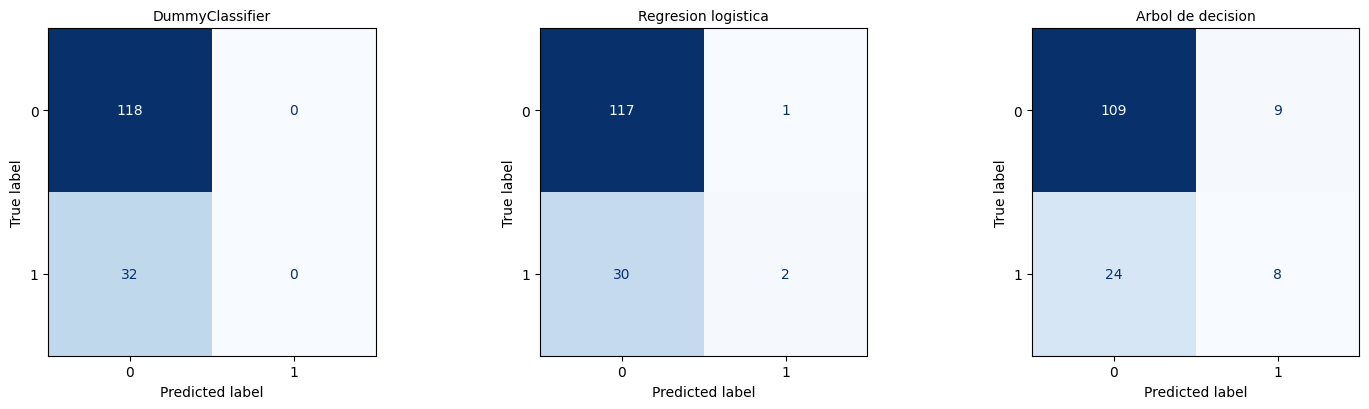

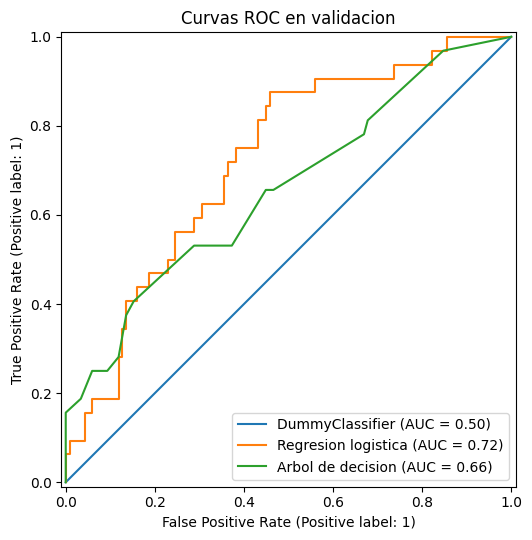

In [ ]:
# 17. Evaluación de los modelos graficas

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for ax, (nombre, modelo) in zip(axes, modelos.items()):
    y_pred = modelo.predict(X_val)
    cm = confusion_matrix(y_val, y_pred)
    ConfusionMatrixDisplay(cm).plot(ax=ax, colorbar=False, cmap='Blues')
    ax.set_title(nombre, fontsize=10)
plt.tight_layout()
plt.show()


from sklearn.metrics import RocCurveDisplay

fig, ax = plt.subplots(figsize=(6,5.5))
for nombre, modelo in modelos.items():
    RocCurveDisplay.from_estimator(modelo, X_val, y_val, ax=ax, name=nombre)
plt.title('Curvas ROC en validacion')
plt.tight_layout()
plt.show()


In [ ]:
# 19. Análisis del umbral

y_proba_lr = log_reg_pipeline.predict_proba(X_val)[:, 1]

for u in [0.50, 0.30]:
    y_pred_u = (y_proba_lr >= u).astype(int)
    print(u,
          precision_score(y_val, y_pred_u),
          recall_score(y_val, y_pred_u),
          f1_score(y_val, y_pred_u))

0.5 0.6666666666666666 0.0625 0.11428571428571428
0.3 0.4230769230769231 0.34375 0.3793103448275862
